# Machine Learning Lab Midterm Project
**Taha Ali Khan · BS Business Data Analytics · Semester 5 · COMSATS University Islamabad**

This notebook is the main project. All preparation, training, evaluation, plots and exports are visible here. **It never imports the project backend.** The website is only a small demonstration of three exported prediction pipelines.

Run cells in order using the project Python environment. No web server is needed to run the notebook. The three real datasets are included. Original sources, schemas and licenses are in `data/SOURCES.md` and `data/LICENSE_DATA.md`.

**Learning order:** inspect → split → prepare → train → evaluate → interpret → export.

Only the clearly labelled seven-day ordered-fill example is synthetic; SMOTE also creates explicitly labelled synthetic training observations.

## 1. Imports, paths and small display helpers
The functions below only reduce repeated display and metric code. The actual modelling steps remain visible in later cells. Fixed seed 42 makes the split reproducible.

In [22]:
from pathlib import Path
from io import BytesIO
import json
import platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    OneHotEncoder,
    LabelEncoder,
    PolynomialFeatures,
)
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.feature_selection import RFE
from sklearn.decomposition import PCA
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve,
    brier_score_loss,
)

ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "data").is_dir():
    raise ValueError("Open this notebook inside the ml_lab project folder.")
SEED = 42
results = {}


def show_plot():
    """Display the current real plot and close it, avoiding accumulated figures."""
    buffer = BytesIO()
    plt.tight_layout()
    plt.savefig(buffer, format="png", dpi=110)
    display(Image(data=buffer.getvalue()))
    plt.close()


def record(name, rows):
    table = pd.DataFrame(rows)
    results[name] = json.loads(table.to_json(orient="records"))
    display(table)


def classification_metrics(model, X, y, threshold=0.5):
    probability = model.predict_proba(X)[:, 1]
    predicted = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    return {
        "accuracy": float(accuracy_score(y, predicted)),
        "precision": float(precision_score(y, predicted, zero_division=0)),
        "recall": float(recall_score(y, predicted, zero_division=0)),
        "specificity": float(tn / (tn + fp)),
        "f1": float(f1_score(y, predicted, zero_division=0)),
        "roc_auc": float(roc_auc_score(y, probability)),
        "brier": float(brier_score_loss(y, probability)),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }


print("Python", platform.python_version(), "· seed", SEED)


Python 3.14.2 · seed 42


## 2. Inspect three real datasets
Auto MPG predicts a continuous fuel-efficiency measurement. Bank Marketing predicts subscription yes/no. Yelp sentences predict positive/negative sentiment. No made-up regression target is needed.

Auto MPG (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite


Bank Marketing (4521, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no


Yelp reviews (1000, 2)


,text,sentiment
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


,missing
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
car_name,0


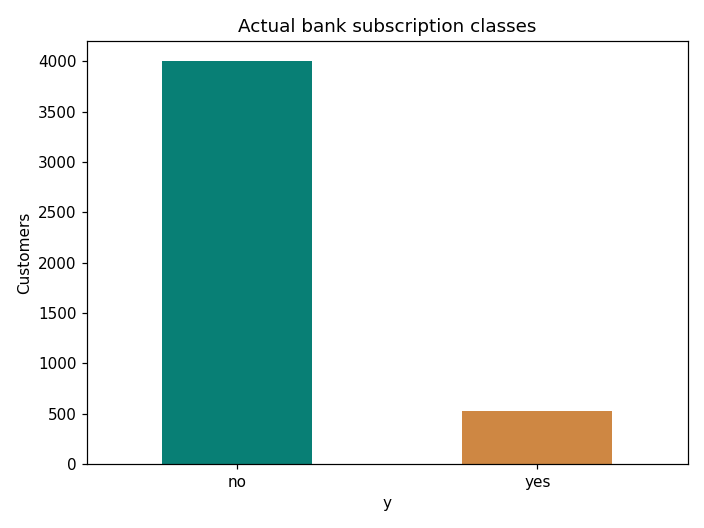

In [23]:
cars = pd.read_csv(ROOT / "data/auto_mpg.csv")
bank = pd.read_csv(ROOT / "data/bank.csv", sep=";")
reviews = pd.read_csv(ROOT / "data/reviews.csv")
for name, data in [
    ("Auto MPG", cars),
    ("Bank Marketing", bank),
    ("Yelp reviews", reviews),
]:
    print(name, data.shape)
    display(data.head(3))
display(cars.describe())
display(cars.isna().sum().rename("missing").to_frame())
bank["y"].value_counts().plot.bar(color=["#087f75", "#ce8743"], rot=0)
plt.title("Actual bank subscription classes")
plt.ylabel("Customers")
show_plot()


## 3. Split first, then fit preparation on training rows
Use a 75/25 split. Stratify classification so both classes are represented. Bank `unknown` is a missing category. Exclude call `duration`: it would not be available before a marketing call. Day-of-month and IDs are also excluded.

Whole-data inspection above is descriptive; it does not fit any predictive transformation.

In [24]:
car_features = [
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year",
]
car_train, car_test, mpg_train, mpg_test = train_test_split(
    cars[car_features], cars["mpg"], test_size=0.25, random_state=SEED
)

numeric = ["age", "balance", "campaign", "pdays", "previous"]
categorical = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "poutcome",
]
bank_X = bank[numeric + categorical].replace("unknown", np.nan)
bank_y = bank["y"].eq("yes").astype(int)
bank_train, bank_test, y_train, y_test = train_test_split(
    bank_X, bank_y, test_size=0.25, stratify=bank_y, random_state=SEED
)
print("Cars train/test:", len(car_train), len(car_test))
print("Bank train/test:", len(bank_train), len(bank_test))
# pdays=-1 means no previous campaign contact; it is retained as a documented sentinel.


Cars train/test: 298 100
Bank train/test: 3390 1131


## 4. Missing values: deletion and mean/median/mode
Use the real missing horsepower values. Learn each replacement statistic from training cars only. Categorical mode is demonstrated on real missing bank education values.

In [25]:
record(
    "deletion",
    [
        {"split": "train", "before": len(car_train), "after": len(car_train.dropna())},
        {"split": "test", "before": len(car_test), "after": len(car_test.dropna())},
    ],
)
imputation_rows = []
for strategy in ["mean", "median", "most_frequent"]:
    imputer = SimpleImputer(strategy=strategy).fit(car_train[["horsepower"]])
    filled = imputer.transform(car_test[["horsepower"]])
    imputation_rows.append(
        {
            "method": strategy,
            "train_replacement": float(imputer.statistics_[0]),
            "test_missing_after": int(np.isnan(filled).sum()),
        }
    )
record("imputation", imputation_rows)
mode_imputer = SimpleImputer(strategy="most_frequent").fit(bank_train[["education"]])
record(
    "categorical_mode",
    [
        {
            "column": "education",
            "training_missing": int(bank_train.education.isna().sum()),
            "replacement": str(mode_imputer.statistics_[0]),
        }
    ],
)


,split,before,after
0,train,298,293
1,test,100,99


,method,train_replacement,test_missing_after
0,mean,103.211604,0
1,median,92.000000,0
2,most_frequent,90.000000,0


,column,training_missing,replacement
0,education,142,secondary


### KNN imputation
Nearby training rows estimate the gaps. Scale all numeric features first so large measurement units do not dominate distance. StandardScaler preserves NaNs, allowing KNNImputer to handle them afterward.

In [26]:
knn_scale = StandardScaler().fit(car_train)
knn_imputer = KNNImputer(n_neighbors=5).fit(knn_scale.transform(car_train))
knn_train = knn_scale.inverse_transform(
    knn_imputer.transform(knn_scale.transform(car_train))
)
knn_imputer.transform(knn_scale.transform(car_test))
missing = car_train["horsepower"].isna().to_numpy()
record(
    "knn_imputation",
    [
        {"row": int(index), "horsepower_estimate": float(value)}
        for index, value in zip(car_train.index[missing], knn_train[missing, 2])
    ],
)


,row,horsepower_estimate
0,336,91.2
1,374,77.2
2,32,63.8
3,354,76.4
4,330,63.2


### Forward fill, backward fill and interpolation — synthetic lesson only
Independent customer rows have no meaningful time order. These seven daily values are invented only to explain ordered filling. They never enter a model or its scores. Backward fill and interpolation can use future observations and leak information in forecasting.

In [27]:
series = pd.Series(
    [10.0, np.nan, 14.0, np.nan, np.nan, 20.0, np.nan],
    index=pd.date_range("2026-01-01", periods=7),
)
filled_series = pd.DataFrame(
    {
        "date": series.index.strftime("%Y-%m-%d"),
        "original": series.values,
        "forward_fill": series.ffill().values,
        "backward_fill": series.bfill().values,
        "interpolation": series.interpolate(limit_area="inside").values,
    }
)
record("synthetic_ordered_fill", filled_series.to_dict("records"))


,date,original,forward_fill,backward_fill,interpolation
0,2026-01-01,10.0,10.0,10.0,10.0
1,2026-01-02,NaN,10.0,14.0,12.0
2,2026-01-03,14.0,14.0,14.0,14.0
3,2026-01-04,NaN,14.0,20.0,16.0
4,2026-01-05,NaN,14.0,20.0,18.0
5,2026-01-06,20.0,20.0,20.0,20.0
6,2026-01-07,NaN,20.0,NaN,NaN


## 5. Scaling and categorical encoding
Min-Max uses training minima/maxima; standardization uses training mean/standard deviation; robust scaling uses median/IQR. Unseen Min-Max values may fall outside [0,1].

One-hot encoding is appropriate for unordered job categories. Label encoding features is shown as a demonstration, not used to imply that jobs have an order. Counts and frequencies are learned from training categories only.

In [28]:
numeric_imputer = SimpleImputer(strategy="median").fit(car_train)
filled_train = numeric_imputer.transform(car_train)
filled_test = numeric_imputer.transform(car_test)
scale_table = {"weight_before": car_test.weight.to_numpy()[:5]}
for name, scaler in [
    ("minmax", MinMaxScaler()),
    ("standard", StandardScaler()),
    ("robust", RobustScaler()),
]:
    scaler.fit(filled_train)
    scale_table[name] = scaler.transform(filled_test)[:5, 3]
record("scaling", pd.DataFrame(scale_table).to_dict("records"))

job_imputer = SimpleImputer(strategy="most_frequent").fit(bank_train[["job"]])
job_train = job_imputer.transform(bank_train[["job"]]).ravel()
job_test = job_imputer.transform(bank_test[["job"]]).ravel()
encoder = LabelEncoder().fit(job_train)
label_map = {label: int(i) for i, label in enumerate(encoder.classes_)}
counts = pd.Series(job_train).value_counts()
record(
    "encoding",
    [
        {
            "job": job,
            "label_demo": label_map.get(job, -1),
            "count": int(counts.get(job, 0)),
            "frequency": float(counts.get(job, 0) / len(job_train)),
        }
        for job in job_test[:8]
    ],
)
onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(
    job_train.reshape(-1, 1)
)
display(
    pd.DataFrame(
        onehot.transform(job_test[:5].reshape(-1, 1)),
        columns=onehot.get_feature_names_out(["job"]),
    )
)


,weight_before,minmax,standard,robust
0,1795.0,0.051602,-1.421474,-0.785663
1,2625.0,0.286929,-0.424753,-0.184649
2,2634.0,0.289481,-0.413945,-0.178132
3,3940.0,0.659768,1.154390,0.767560
4,4237.0,0.743975,1.511048,0.982621


,job,label_demo,count,frequency
0,management,4,755,0.222714
1,retired,5,154,0.045428
2,management,4,755,0.222714
3,management,4,755,0.222714
4,technician,9,600,0.176991
5,student,8,55,0.016224
6,services,7,303,0.089381
7,blue-collar,1,723,0.213274


,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed
0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


## 6. Reusable preparation pipelines, RFE, importance and PCA
RFE keeps original features; PCA creates new combinations. The selection demonstration uses the five numeric bank features. Its labels come from training only.

,feature,selected,rank
0,age,True,1
1,balance,False,3
2,campaign,True,1
3,pdays,False,2
4,previous,True,1


,feature,importance
0,age,0.297220
1,balance,0.225248
2,campaign,0.069696
3,pdays,0.269167
4,previous,0.138669


,component,variance_explained
0,1,0.325654
1,2,0.216165


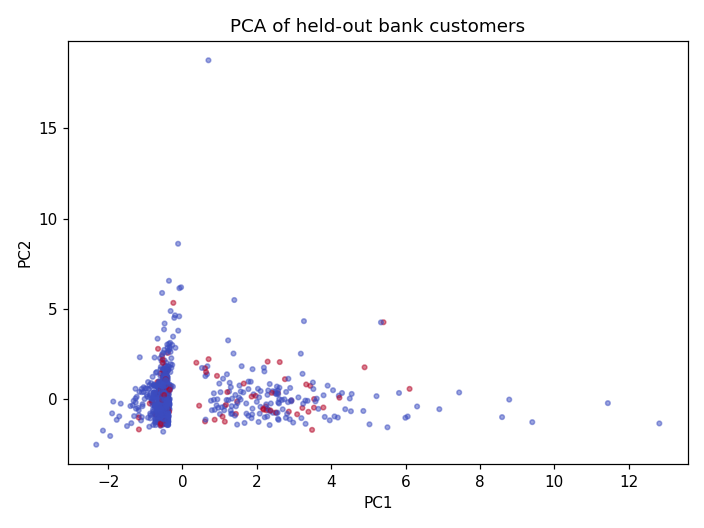

In [29]:
def bank_preparation(numeric_only=False):
    numeric_steps = Pipeline(
        [("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]
    )
    transformers = [("numeric", numeric_steps, numeric)]
    if not numeric_only:
        categorical_steps = Pipeline(
            [
                ("impute", SimpleImputer(strategy="most_frequent")),
                ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]
        )
        transformers.append(("category", categorical_steps, categorical))
    return ColumnTransformer(transformers, verbose_feature_names_out=False)


def bank_pipeline(estimator, numeric_only=False):
    return Pipeline([("prepare", bank_preparation(numeric_only)), ("model", estimator)])


feature_preparation = bank_preparation(numeric_only=True)
a = feature_preparation.fit_transform(bank_train[numeric], y_train)
b = feature_preparation.transform(bank_test[numeric])
rfe = RFE(LogisticRegression(max_iter=1500), n_features_to_select=3).fit(a, y_train)
record(
    "rfe",
    [
        {"feature": name, "selected": bool(keep), "rank": int(rank)}
        for name, keep, rank in zip(numeric, rfe.support_, rfe.ranking_)
    ],
)
importance_model = RandomForestClassifier(
    n_estimators=60, max_depth=6, random_state=SEED, n_jobs=1
).fit(a, y_train)
record(
    "numeric_importance",
    [
        {"feature": name, "importance": float(value)}
        for name, value in zip(numeric, importance_model.feature_importances_)
    ],
)
pca = PCA(n_components=2).fit(a)
components = pca.transform(b)
record(
    "pca",
    [
        {"component": i + 1, "variance_explained": float(value)}
        for i, value in enumerate(pca.explained_variance_ratio_)
    ],
)
plt.scatter(
    components[:, 0], components[:, 1], c=y_test, cmap="coolwarm", s=9, alpha=0.5
)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of held-out bank customers")
show_plot()


## 7. Regression: predict real MPG
Simple linear uses weight alone. Multiple linear uses six vehicle attributes. Polynomial bends the weight relationship. Ridge penalizes squared coefficient sizes; Lasso penalizes absolute sizes and can eliminate coefficients. Alpha controls the penalty. All preparation fits only training cars.

R² compares against a mean prediction; MAE and RMSE are in MPG. Lower errors are better. The deployment model is fixed as multiple linear regression in advance, not chosen from the test results.

,model,r2,mae,rmse
0,Simple linear,0.727722,3.210920,3.932032
1,Multiple linear,0.827189,2.529206,3.132543
2,Polynomial degree 2,0.762587,2.843263,3.671667
3,Ridge,0.827325,2.530024,3.131308
4,Lasso,0.833763,2.390049,3.072382
5,Regression tree,0.791510,2.408425,3.440755


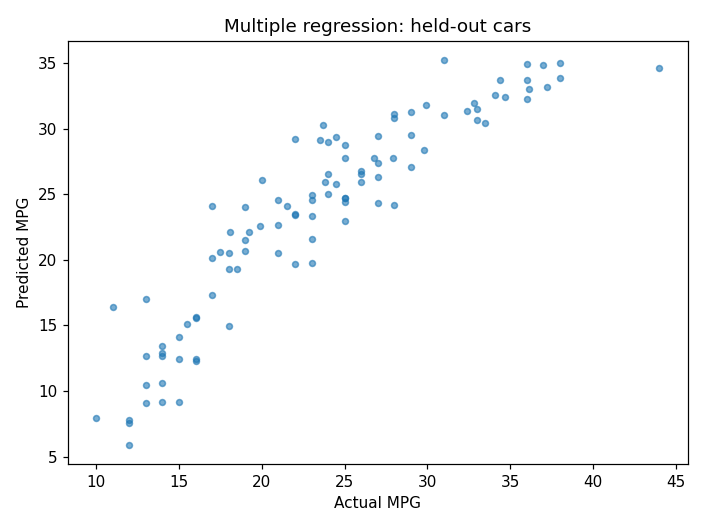

In [30]:
regression_models = {
    "Simple linear": (["weight"], LinearRegression(), 1),
    "Multiple linear": (car_features, LinearRegression(), 1),
    "Polynomial degree 2": (["weight"], LinearRegression(), 2),
    "Ridge": (car_features, Ridge(alpha=1.0), 1),
    "Lasso": (car_features, Lasso(alpha=1.0, max_iter=10000), 1),
    "Regression tree": (
        car_features,
        DecisionTreeRegressor(max_depth=4, random_state=SEED),
        1,
    ),
}
regression_rows = []
for name, (columns, estimator, degree) in regression_models.items():
    pipeline = Pipeline(
        [
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("polynomial", PolynomialFeatures(degree=degree, include_bias=False)),
            ("model", estimator),
        ]
    )
    pipeline.fit(car_train[columns], mpg_train)
    prediction = pipeline.predict(car_test[columns])
    regression_rows.append(
        {
            "model": name,
            "r2": float(r2_score(mpg_test, prediction)),
            "mae": float(mean_absolute_error(mpg_test, prediction)),
            "rmse": float(np.sqrt(mean_squared_error(mpg_test, prediction))),
        }
    )
    if name == "Multiple linear":
        fuel_model = pipeline
record("regression", regression_rows)
plt.scatter(mpg_test, fuel_model.predict(car_test), s=15, alpha=0.6)
plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Multiple regression: held-out cars")
show_plot()


### Underfitting and overfitting
A more complex curve can lower training error while increasing test error. High accuracy alone does not establish overfitting. These preset comparisons illustrate the idea; repeated test inspection should not be claimed as unbiased final model selection.

,degree,train_rmse,test_rmse
0,1,4.463479,3.932032
1,2,4.326630,3.671667
2,3,4.325518,3.681345
3,5,4.320914,3.672566
4,10,4.310262,3.626472
5,15,4.303076,3.580359


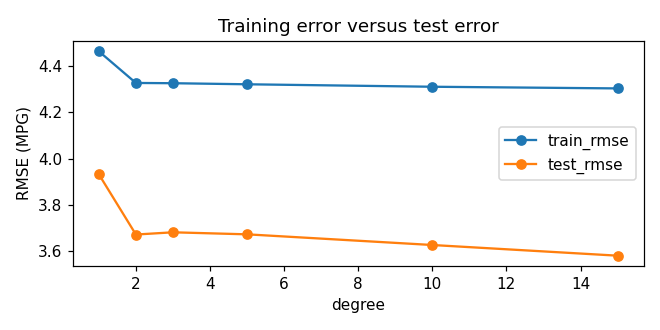

In [31]:
complexity_rows = []
for degree in [1, 2, 3, 5, 10, 15]:
    polynomial_model = Pipeline(
        [
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
            ("model", LinearRegression()),
        ]
    ).fit(car_train[["weight"]], mpg_train)
    complexity_rows.append(
        {
            "degree": degree,
            "train_rmse": float(
                np.sqrt(
                    mean_squared_error(
                        mpg_train, polynomial_model.predict(car_train[["weight"]])
                    )
                )
            ),
            "test_rmse": float(
                np.sqrt(
                    mean_squared_error(
                        mpg_test, polynomial_model.predict(car_test[["weight"]])
                    )
                )
            ),
        }
    )
record("complexity", complexity_rows)
complexity_table = pd.DataFrame(complexity_rows).set_index("degree")
complexity_table.plot(marker="o", figsize=(6, 3))
plt.ylabel("RMSE (MPG)")
plt.title("Training error versus test error")
show_plot()


## 8. Logistic classification, probabilities and thresholds
The positive class means a customer subscribes. Precision asks how many flagged customers subscribed. Recall asks how many actual subscribers were found. Specificity measures correct rejection of negatives. F1 balances precision/recall; ROC-AUC measures ranking across thresholds.

A lower threshold may increase subscribers found and unnecessary calls. It is an illustration, not a threshold optimized on the test set.

,threshold,accuracy,precision,recall,specificity,f1,roc_auc,brier,tn,fp,fn,tp
0,0.2,0.848806,0.327731,0.300000,0.920080,0.313253,0.700215,0.094174,921,80,91,39
1,0.3,0.872679,0.400000,0.215385,0.958042,0.280000,0.700215,0.094174,959,42,102,28
2,0.5,0.887710,0.540541,0.153846,0.983017,0.239521,0.700215,0.094174,984,17,110,20
3,0.7,0.888594,0.625000,0.076923,0.994006,0.136986,0.700215,0.094174,995,6,120,10


,Predicted no,Predicted yes
Actual no,984,17
Actual yes,110,20


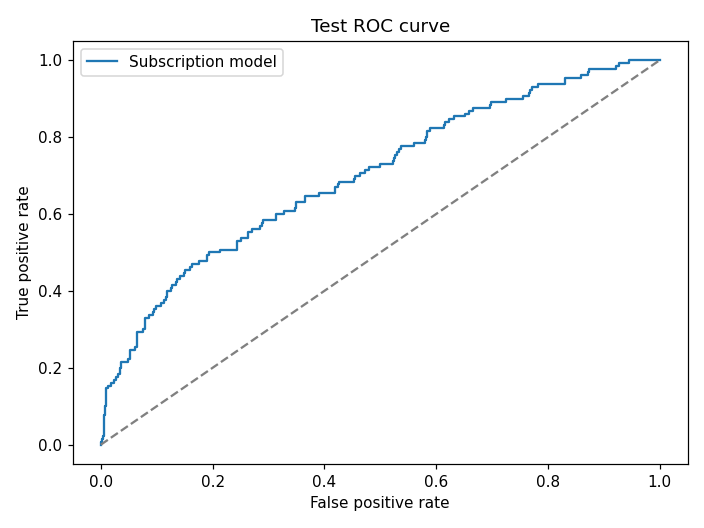

In [32]:
subscription_full = bank_pipeline(LogisticRegression(max_iter=1500, random_state=SEED))
subscription_full.fit(bank_train, y_train)
threshold_rows = [
    {
        "threshold": threshold,
        **classification_metrics(subscription_full, bank_test, y_test, threshold),
    }
    for threshold in [0.2, 0.3, 0.5, 0.7]
]
record("classification", threshold_rows)
probability = subscription_full.predict_proba(bank_test)[:, 1]
predicted = (probability >= 0.5).astype(int)
cm = confusion_matrix(y_test, predicted, labels=[0, 1])
display(
    pd.DataFrame(
        cm, index=["Actual no", "Actual yes"], columns=["Predicted no", "Predicted yes"]
    )
)
fpr, tpr, _ = roc_curve(y_test, probability)
plt.plot(fpr, tpr, label="Subscription model")
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Test ROC curve")
plt.legend()
show_plot()


### A clearly separate decision-boundary lesson
For an easy-to-see two-dimensional boundary, use real vehicle weight and horsepower to classify whether a car has **at least six cylinders**. This is a separate task; the plot does not claim to represent the bank model's performance.

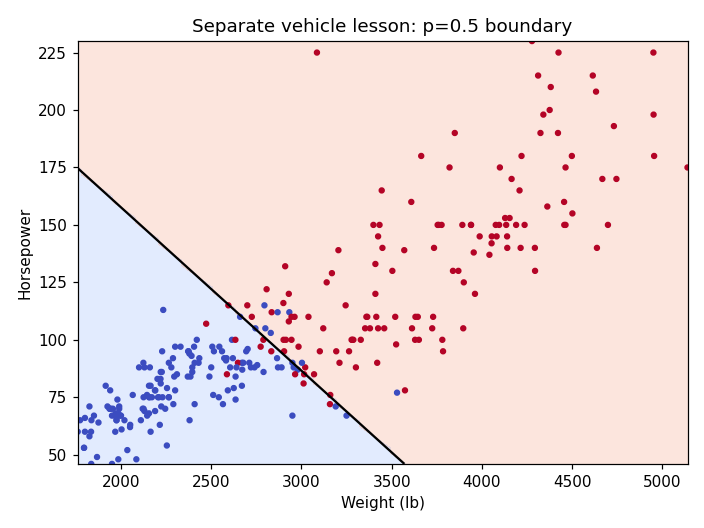

In [33]:
vehicle_X = cars[["weight", "horsepower"]]
vehicle_y = cars.cylinders.ge(6).astype(int)
v_train, v_test, vy_train, vy_test = train_test_split(
    vehicle_X, vehicle_y, test_size=0.25, stratify=vehicle_y, random_state=SEED
)
boundary_model = Pipeline(
    [
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(class_weight="balanced", random_state=SEED)),
    ]
).fit(v_train, vy_train)
weight_grid, horsepower_grid = np.meshgrid(
    np.linspace(v_train.weight.min(), v_train.weight.max(), 80),
    np.linspace(v_train.horsepower.min(), v_train.horsepower.max(), 80),
)
grid = pd.DataFrame(
    {"weight": weight_grid.ravel(), "horsepower": horsepower_grid.ravel()}
)
region_probability = boundary_model.predict_proba(grid)[:, 1].reshape(weight_grid.shape)
plt.contourf(
    weight_grid, horsepower_grid, region_probability >= 0.5, alpha=0.25, cmap="coolwarm"
)
plt.contour(
    weight_grid, horsepower_grid, region_probability, levels=[0.5], colors="black"
)
plt.scatter(v_train.weight, v_train.horsepower, c=vy_train, cmap="coolwarm", s=10)
plt.xlabel("Weight (lb)")
plt.ylabel("Horsepower")
plt.title("Separate vehicle lesson: p=0.5 boundary")
show_plot()


## 9. Decision trees, rules and pruning
Entropy = −Σp log₂p; Gini = 1−Σp². Information gain is parent entropy minus weighted child entropy. Compute them at an actual training root. Limiting depth is pre-pruning; ccp_alpha controls cost-complexity post-pruning.

The shared preparation scales numeric features. Numeric thresholds in extracted rules are standardized values; one-hot indicators remain 0/1.

In [34]:
tree_estimators = {
    "Tree Gini": DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "Tree entropy": DecisionTreeClassifier(
        criterion="entropy", max_depth=4, random_state=SEED
    ),
    "Unrestricted tree": DecisionTreeClassifier(random_state=SEED),
    "Pruned tree": DecisionTreeClassifier(ccp_alpha=0.001, random_state=SEED),
}
fitted_trees = {}
tree_rows = []
for name, estimator in tree_estimators.items():
    pipeline = bank_pipeline(estimator).fit(bank_train, y_train)
    fitted_trees[name] = pipeline
    tree_rows.append(
        {
            "model": name,
            "train_accuracy": float(pipeline.score(bank_train, y_train)),
            **classification_metrics(pipeline, bank_test, y_test),
        }
    )
record("trees", tree_rows)
explained_tree = fitted_trees["Tree entropy"]
tree = explained_tree.named_steps["model"]
feature_names = explained_tree.named_steps["prepare"].get_feature_names_out()
print(export_text(tree, feature_names=list(feature_names), max_depth=3))


def entropy(labels):
    fractions = np.bincount(np.asarray(labels, dtype=int), minlength=2) / len(labels)
    fractions = fractions[fractions > 0]
    return float(-np.sum(fractions * np.log2(fractions)))


transformed_train = explained_tree.named_steps["prepare"].transform(bank_train)
root_feature, root_limit = tree.tree_.feature[0], tree.tree_.threshold[0]
goes_left = transformed_train[:, root_feature] <= root_limit
weighted_entropy = goes_left.mean() * entropy(y_train[goes_left]) + (
    ~goes_left
).mean() * entropy(y_train[~goes_left])
p = float(y_train.mean())
record(
    "tree_math",
    [
        {
            "root_split": f"{feature_names[root_feature]} <= {root_limit:.4f}",
            "entropy": entropy(y_train),
            "gini": 1 - p * p - (1 - p) ** 2,
            "weighted_child_entropy": float(weighted_entropy),
            "information_gain": float(entropy(y_train) - weighted_entropy),
        }
    ],
)


,model,train_accuracy,accuracy,precision,recall,specificity,f1,roc_auc,brier,tn,fp,fn,tp
0,Tree Gini,0.89823,0.872679,0.400000,0.215385,0.958042,0.280000,0.607673,0.098702,959,42,102,28
1,Tree entropy,0.89823,0.872679,0.400000,0.215385,0.958042,0.280000,0.647691,0.097958,959,42,102,28
2,Unrestricted tree,1.00000,0.815208,0.211679,0.223077,0.892108,0.217228,0.557592,0.184792,893,108,101,29
3,Pruned tree,0.89587,0.880637,0.459016,0.215385,0.967033,0.293194,0.665273,0.094738,968,33,102,28


|--- poutcome_success <= 0.50
|   |--- month_oct <= 0.50
|   |   |--- age <= 1.87
|   |   |   |--- marital_married <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- marital_married >  0.50
|   |   |   |   |--- class: 0
|   |   |--- age >  1.87
|   |   |   |--- balance <= -0.16
|   |   |   |   |--- class: 0
|   |   |   |--- balance >  -0.16
|   |   |   |   |--- class: 1
|   |--- month_oct >  0.50
|   |   |--- job_blue-collar <= 0.50
|   |   |   |--- balance <= 1.62
|   |   |   |   |--- class: 1
|   |   |   |--- balance >  1.62
|   |   |   |   |--- class: 0
|   |   |--- job_blue-collar >  0.50
|   |   |   |--- class: 0
|--- poutcome_success >  0.50
|   |--- balance <= 3.27
|   |   |--- job_management <= 0.50
|   |   |   |--- age <= -1.06
|   |   |   |   |--- class: 1
|   |   |   |--- age >  -1.06
|   |   |   |   |--- class: 1
|   |   |--- job_management >  0.50
|   |   |   |--- previous <= 1.90
|   |   |   |   |--- class: 1
|   |   |   |--- previous >  1.90
|   |   |   |   |--- clas

,root_split,entropy,gini,weighted_child_entropy,information_gain
0,poutcome_success <= 0.5000,0.515814,0.204072,0.479043,0.03677


### Random Forest and boosting
Random Forest combines bootstrap samples and feature randomness. AdaBoost reweights hard examples. Gradient boosting adds corrections sequentially. XGBoost and LightGBM are efficient boosted-tree implementations. Keep small CPU configurations; do not claim exhaustive tuning.

In [35]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

ensemble_estimators = {
    "Random forest": RandomForestClassifier(
        n_estimators=80, max_depth=6, random_state=SEED, n_jobs=1
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=50, learning_rate=0.5, random_state=SEED
    ),
    "Gradient boosting": GradientBoostingClassifier(
        n_estimators=60, max_depth=2, random_state=SEED
    ),
    "XGBoost": XGBClassifier(
        n_estimators=60,
        max_depth=3,
        learning_rate=0.1,
        random_state=SEED,
        n_jobs=1,
        eval_metric="logloss",
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=60,
        max_depth=3,
        num_leaves=8,
        verbosity=-1,
        random_state=SEED,
        n_jobs=1,
    ),
}
ensemble_rows = []
for name, estimator in ensemble_estimators.items():
    pipeline = bank_pipeline(estimator).fit(bank_train, y_train)
    ensemble_rows.append(
        {"model": name, **classification_metrics(pipeline, bank_test, y_test)}
    )
record("ensembles", ensemble_rows)


C:\Users\pc\Downloads\ML_Labmid_Sp24_142\ml_lab\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,model,accuracy,precision,recall,specificity,f1,roc_auc,brier,tn,fp,fn,tp
0,Random forest,0.890363,0.636364,0.107692,0.992008,0.184211,0.704580,0.091732,993,8,116,14
1,AdaBoost,0.890363,0.600000,0.138462,0.988012,0.225000,0.705506,0.106763,989,12,112,18
2,Gradient boosting,0.890363,0.583333,0.161538,0.985015,0.253012,0.712937,0.093171,986,15,109,21
3,XGBoost,0.882405,0.459459,0.130769,0.980020,0.203593,0.696227,0.093893,981,20,113,17
4,LightGBM,0.885942,0.512821,0.153846,0.981019,0.236686,0.699800,0.093126,982,19,110,20


## 10. Small SVM and Gaussian Naive Bayes comparison
Use five numeric bank features for simplicity. SVM kernels: linear, degree-2 polynomial and RBF. C penalizes margin violations; gamma controls local RBF influence. Compare scaled versus unscaled RBF.

Gaussian NB assumes conditional independence and approximately normal numeric features within a class. Bayes: posterior ∝ prior × likelihood. These imperfect assumptions make it a baseline, not a guaranteed best model.

In [36]:
svm_estimators = {
    "SVM linear": SVC(kernel="linear", C=1, probability=True, random_state=SEED),
    "SVM polynomial": SVC(
        kernel="poly", degree=2, C=1, probability=True, random_state=SEED
    ),
    "SVM RBF": SVC(kernel="rbf", C=1, probability=True, random_state=SEED),
    "RBF balanced": SVC(
        kernel="rbf", C=1, class_weight="balanced", probability=True, random_state=SEED
    ),
    "Gaussian NB": GaussianNB(),
}
svm_rows = []
margin_rows = []
for name, estimator in svm_estimators.items():
    pipeline = bank_pipeline(estimator, numeric_only=True).fit(
        bank_train[numeric], y_train
    )
    svm_rows.append(
        {"model": name, **classification_metrics(pipeline, bank_test[numeric], y_test)}
    )
    margin_rows.append(
        {
            "model": name,
            "positive_by_predict": int(
                np.sum(pipeline.predict(bank_test[numeric]) == 1)
            ),
            "positive_by_probability_0_5": int(
                np.sum(pipeline.predict_proba(bank_test[numeric])[:, 1] >= 0.5)
            ),
        }
    )
unscaled_rbf = Pipeline(
    [
        ("impute", SimpleImputer(strategy="median")),
        ("model", SVC(kernel="rbf", probability=True, random_state=SEED)),
    ]
).fit(bank_train[numeric], y_train)
svm_rows.append(
    {
        "model": "RBF unscaled",
        **classification_metrics(unscaled_rbf, bank_test[numeric], y_test),
    }
)
record("svm_nb", svm_rows)
record("svm_decisions", margin_rows)
# SVC margins and fitted probability estimates can disagree. Zero recall at p>=0.5 is a real result.
sensitivity_rows = []
for C, gamma in [(0.1, 0.01), (1, 0.01), (10, 0.01), (1, 1)]:
    pipeline = bank_pipeline(
        SVC(C=C, gamma=gamma, probability=True, random_state=SEED), True
    )
    pipeline.fit(bank_train[numeric], y_train)
    sensitivity_rows.append(
        {
            "C": C,
            "gamma": gamma,
            **classification_metrics(pipeline, bank_test[numeric], y_test),
        }
    )
record("svm_sensitivity", sensitivity_rows)


,model,accuracy,precision,recall,specificity,f1,roc_auc,brier,tn,fp,fn,tp
0,SVM linear,0.885057,0.000000,0.000000,1.000000,0.000000,0.452036,0.101770,1001,0,130,0
1,SVM polynomial,0.881521,0.000000,0.000000,0.996004,0.000000,0.536298,0.104201,997,4,130,0
2,SVM RBF,0.884173,0.000000,0.000000,0.999001,0.000000,0.552644,0.101905,1000,1,130,0
3,RBF balanced,0.885057,0.000000,0.000000,1.000000,0.000000,0.647395,0.096845,1001,0,130,0
4,Gaussian NB,0.827586,0.207207,0.176923,0.912088,0.190871,0.624979,0.135992,913,88,107,23
5,RBF unscaled,0.885057,0.000000,0.000000,1.000000,0.000000,0.426969,0.101735,1001,0,130,0


,model,positive_by_predict,positive_by_probability_0_5
0,SVM linear,0,0
1,SVM polynomial,0,4
2,SVM RBF,1,1
3,RBF balanced,186,0
4,Gaussian NB,111,111


,C,gamma,accuracy,precision,recall,specificity,f1,roc_auc,brier,tn,fp,fn,tp
0,0.1,0.01,0.885057,0.0,0.000000,1.0,0.000000,0.496454,0.101784,1001,0,130,0
1,1.0,0.01,0.885057,0.0,0.000000,1.0,0.000000,0.579378,0.101774,1001,0,130,0
2,10.0,0.01,0.885057,0.0,0.000000,1.0,0.000000,0.613706,0.101779,1001,0,130,0
3,1.0,1.00,0.886826,1.0,0.015385,1.0,0.030303,0.519146,0.099126,1001,0,128,2


## 11. Imbalance, thresholds, SMOTE and calibration
A majority-only classifier can have high accuracy but zero subscriber recall. Compare error weighting, synthetic numeric training examples, and a fixed threshold.

SMOTE is inside a training pipeline. Calibration wraps the **entire** preparation pipeline in three training folds. The test set is never resampled or used to fit a probability correction. Brier score measures probability error; lower is better. Ordinary numeric logistic regression is fixed in advance for the small website.

,model,threshold,accuracy,precision,recall,specificity,f1,roc_auc,brier,tn,fp,fn,tp
0,Majority baseline,0.5,0.885057,0.000000,0.000000,1.000000,0.000000,0.500000,0.101731,1001,0,130,0
1,Logistic baseline,0.5,0.880637,0.142857,0.007692,0.994006,0.014599,0.596031,0.101951,995,6,129,1
2,Class weighting,0.5,0.687887,0.171091,0.446154,0.719281,0.247335,0.603162,0.239348,720,281,72,58
3,SMOTE,0.5,0.672856,0.168508,0.469231,0.699301,0.247967,0.601018,0.238372,700,301,69,61
4,Weighted + calibration,0.5,0.879752,0.125000,0.007692,0.993007,0.014493,0.603093,0.102513,994,7,129,1
5,Baseline threshold 0.3,0.3,0.871795,0.142857,0.023077,0.982018,0.039735,0.596031,0.101951,983,18,127,3


,split,no,yes
0,train original,2999,391
1,train after SMOTE,2999,2999
2,test unchanged,1001,130


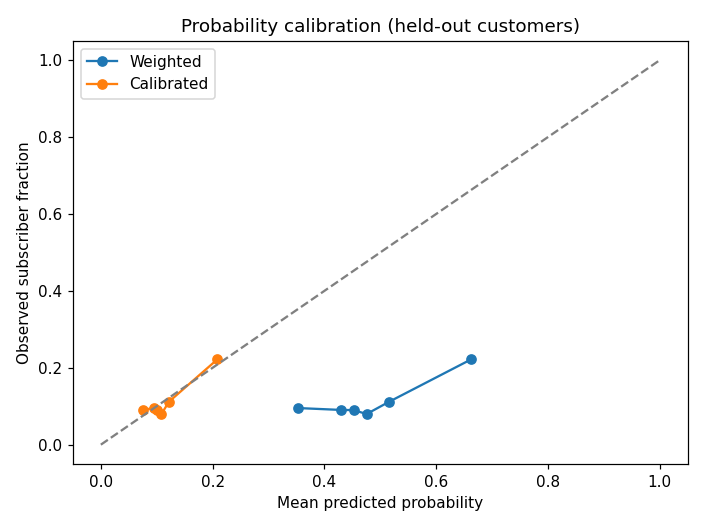

In [37]:
from imblearn.pipeline import Pipeline as SamplingPipeline
from imblearn.over_sampling import SMOTE

baseline = bank_pipeline(LogisticRegression(max_iter=1500, random_state=SEED), True)
weighted = bank_pipeline(
    LogisticRegression(class_weight="balanced", max_iter=1500, random_state=SEED), True
)
smote = SamplingPipeline(
    [
        ("prepare", bank_preparation(True)),
        ("smote", SMOTE(random_state=SEED)),
        ("model", LogisticRegression(max_iter=1500, random_state=SEED)),
    ]
)
calibrated = CalibratedClassifierCV(
    bank_pipeline(
        LogisticRegression(class_weight="balanced", max_iter=1500, random_state=SEED),
        True,
    ),
    method="sigmoid",
    cv=3,
)
imbalance_models = {
    "Majority baseline": bank_pipeline(DummyClassifier(strategy="prior"), True),
    "Logistic baseline": baseline,
    "Class weighting": weighted,
    "SMOTE": smote,
    "Weighted + calibration": calibrated,
}
imbalance_rows = []
for name, pipeline in imbalance_models.items():
    pipeline.fit(bank_train[numeric], y_train)
    imbalance_rows.append(
        {
            "model": name,
            "threshold": 0.5,
            **classification_metrics(pipeline, bank_test[numeric], y_test),
        }
    )
imbalance_rows.append(
    {
        "model": "Baseline threshold 0.3",
        "threshold": 0.3,
        **classification_metrics(baseline, bank_test[numeric], y_test, 0.3),
    }
)
record("imbalance", imbalance_rows)
record(
    "class_counts",
    [
        {
            "split": "train original",
            "no": int((y_train == 0).sum()),
            "yes": int((y_train == 1).sum()),
        },
        {
            "split": "train after SMOTE",
            "no": int((y_train == 0).sum()),
            "yes": int(
                (y_train == 1).sum() + smote.named_steps["smote"].sampling_strategy_[1]
            ),
        },
        {
            "split": "test unchanged",
            "no": int((y_test == 0).sum()),
            "yes": int((y_test == 1).sum()),
        },
    ],
)
for name, pipeline in [("Weighted", weighted), ("Calibrated", calibrated)]:
    observed, predicted = calibration_curve(
        y_test,
        pipeline.predict_proba(bank_test[numeric])[:, 1],
        n_bins=6,
        strategy="quantile",
    )
    plt.plot(predicted, observed, marker="o", label=name)
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed subscriber fraction")
plt.title("Probability calibration (held-out customers)")
plt.legend()
show_plot()


## 12. Text: tokens, counts, stop words and TF-IDF
Deduplicate reviews before splitting so identical text cannot appear in both sets. Fit vocabularies and IDF on training reviews only. A sparse matrix stores mostly zero word counts efficiently.

TF-IDF = tf × [ln((1+N)/(1+document frequency))+1], followed by L2 normalization. Preserve negations such as “not”; bigrams help retain short phrases such as “not good”.

In [38]:
import re
import nltk
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer,
    ENGLISH_STOP_WORDS,
)

nltk.data.path.insert(0, str(ROOT / "data/nltk_data"))
reviews = reviews.dropna(subset=["text", "sentiment"]).copy()
reviews["text"] = reviews.text.astype(str).str.strip()
reviews = reviews[reviews.text.str.len() > 0]
normalized = reviews.text.str.lower().str.replace(r"\s+", " ", regex=True)
conflict = reviews.groupby(normalized).sentiment.transform("nunique") > 1
reviews = reviews.loc[~conflict].copy()
normalized = reviews.text.str.lower().str.replace(r"\s+", " ", regex=True)
reviews = reviews.loc[~normalized.duplicated()]
text_train, text_test, sentiment_train, sentiment_test = train_test_split(
    reviews.text,
    reviews.sentiment.astype(int),
    test_size=0.25,
    stratify=reviews.sentiment,
    random_state=SEED,
)
count_vectorizer = CountVectorizer().fit(text_train)
tfidf_vectorizer = TfidfVectorizer().fit(text_train)
print("Training count matrix:", count_vectorizer.transform(text_train).shape)
example = text_train.iloc[0]
print("Example:", example)
count_values = count_vectorizer.transform([example])
weight_values = tfidf_vectorizer.transform([example])
record(
    "text_vectors",
    [
        {
            "term": term,
            "count": int(count_values[0, count_vectorizer.vocabulary_[term]]),
            "tfidf": float(weight_values[0, tfidf_vectorizer.vocabulary_[term]]),
        }
        for term in count_vectorizer.build_analyzer()(example)
        if term in tfidf_vectorizer.vocabulary_
    ],
)


Training count matrix: (747, 1730)
Example: Love the margaritas, too!


,term,count,tfidf
0,love,1,0.479792
1,the,1,0.176820
2,margaritas,1,0.676709
3,too,1,0.529716


### Stemming, lemmatization and sentiment models
Porter stemming chops endings using rules. WordNet lemmatization uses dictionary forms; this simple example applies verb and noun rules, not contextual POS tagging.

Multinomial NB uses nonnegative token counts and Laplace pseudo-counts. Its independence assumption is a simplification. Calibrated LinearSVC refits its complete vectorizer/classifier pipeline inside each training fold. The website model is fixed as TF-IDF unigrams/bigrams plus logistic regression in advance.

In [39]:
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()


def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())


def stem_tokens(text):
    return [stemmer.stem(token) for token in tokenize(text)]


def lemma_tokens(text):
    return [
        lemmatizer.lemmatize(lemmatizer.lemmatize(token, pos="v"), pos="n")
        for token in tokenize(text)
    ]


record(
    "token_normalization",
    [
        {"token": token, "stem": stemmer.stem(token), "lemma": lemma_tokens(token)[0]}
        for token in tokenize("The waiters were running and the meals were not good.")
    ],
)
stop_words = sorted(set(ENGLISH_STOP_WORDS) - {"not", "no", "nor", "never"})
text_specs = {
    "Bag of words": (CountVectorizer(), LogisticRegression(max_iter=1500)),
    "Stop words removed": (
        CountVectorizer(stop_words=stop_words),
        LogisticRegression(max_iter=1500),
    ),
    "TF-IDF": (TfidfVectorizer(), LogisticRegression(max_iter=1500)),
    "TF-IDF bigrams": (
        TfidfVectorizer(ngram_range=(1, 2)),
        LogisticRegression(max_iter=1500),
    ),
    "Stemming": (
        TfidfVectorizer(tokenizer=stem_tokens, token_pattern=None),
        LogisticRegression(max_iter=1500),
    ),
    "Lemmatization": (
        TfidfVectorizer(tokenizer=lemma_tokens, token_pattern=None),
        LogisticRegression(max_iter=1500),
    ),
    "TF-IDF max_df=0.3": (
        TfidfVectorizer(max_df=0.3),
        LogisticRegression(max_iter=1500),
    ),
    "Linear SVM calibrated": (TfidfVectorizer(), LinearSVC(random_state=SEED)),
    "Multinomial NB alpha=1": (CountVectorizer(), MultinomialNB(alpha=1.0)),
    "Multinomial NB alpha=0.1": (CountVectorizer(), MultinomialNB(alpha=0.1)),
}
text_rows = []
for name, (vectorizer, estimator) in text_specs.items():
    pipeline = Pipeline([("vectorize", vectorizer), ("model", estimator)])
    if name == "Linear SVM calibrated":
        pipeline = CalibratedClassifierCV(pipeline, cv=3)
    pipeline.fit(text_train, sentiment_train)
    text_rows.append(
        {"model": name, **classification_metrics(pipeline, text_test, sentiment_test)}
    )
    if name == "TF-IDF bigrams":
        sentiment_model = pipeline
record("text_models", text_rows)


,token,stem,lemma
0,the,the,the
1,waiters,waiter,waiter
2,were,were,be
3,running,run,run
4,and,and,and
5,the,the,the
6,meals,meal,meal
7,were,were,be
8,not,not,not
9,good,good,good


,model,accuracy,precision,recall,specificity,f1,roc_auc,brier,tn,fp,fn,tp
0,Bag of words,0.807229,0.813008,0.800,0.814516,0.806452,0.889032,0.135569,101,23,25,100
1,Stop words removed,0.819277,0.817460,0.824,0.814516,0.820717,0.895065,0.136608,101,23,22,103
2,TF-IDF,0.775100,0.794872,0.744,0.806452,0.768595,0.869935,0.174407,100,24,32,93
3,TF-IDF bigrams,0.787149,0.790323,0.784,0.790323,0.787149,0.864129,0.189386,98,26,27,98
4,Stemming,0.779116,0.796610,0.752,0.806452,0.773663,0.876000,0.171860,100,24,31,94
5,Lemmatization,0.803213,0.833333,0.760,0.846774,0.794979,0.883613,0.169789,105,19,30,95
6,TF-IDF max_df=0.3,0.795181,0.808333,0.776,0.814516,0.791837,0.875226,0.175156,101,23,28,97
7,Linear SVM calibrated,0.811245,0.825000,0.792,0.830645,0.808163,0.897806,0.133884,103,21,26,99
8,Multinomial NB alpha=1,0.779116,0.769231,0.800,0.758065,0.784314,0.882258,0.143711,94,30,25,100
9,Multinomial NB alpha=0.1,0.803213,0.816667,0.784,0.822581,0.800000,0.881290,0.157661,102,22,27,98


### Influential words, unseen terms and an actual prediction
Coefficients indicate learned associations, not causal effects. The small English review benchmark does not establish reliability for sarcasm, Urdu or a new business domain.

In [40]:
vectorizer = sentiment_model.named_steps["vectorize"]
terms = vectorizer.get_feature_names_out()
coefficients = sentiment_model.named_steps["model"].coef_[0]
order = np.argsort(coefficients)
record(
    "influential_terms",
    [
        {
            "direction": direction,
            "term": str(terms[i]),
            "coefficient": float(coefficients[i]),
        }
        for direction, indices in [
            ("negative", order[:6]),
            ("positive", order[-6:][::-1]),
        ]
        for i in indices
    ],
)
new_review = "The food was delicious and the service was friendly."
print("Positive probability:", float(sentiment_model.predict_proba([new_review])[0, 1]))
unknown = sorted(
    set(vectorizer.build_analyzer()(new_review)) - set(vectorizer.vocabulary_)
)
print("Out-of-vocabulary terms:", unknown)
print("Business use: prioritize potentially negative feedback for a human response.")


,direction,term,coefficient
0,negative,not,-2.300597
1,negative,terrible,-0.976056
2,negative,don,-0.962642
3,negative,there,-0.936854
4,negative,bad,-0.918509
5,negative,worst,-0.862455
6,positive,great,2.451976
7,positive,good,2.015161
8,positive,delicious,1.295965
9,positive,amazing,1.151125


Positive probability: 0.7142451179521137
Out-of-vocabulary terms: []
Business use: prioritize potentially negative feedback for a human response.


## 13. Export three complete pipelines for the small website
The web backend does **no training**. These pipelines include their preprocessing and use only standard sklearn components, so they do not depend on notebook-only tokenizer functions.

Export choices were fixed before test comparisons: multiple linear MPG; ordinary numeric logistic subscription; TF-IDF bigram sentiment. The bank form uses five numeric inputs. Its default decision threshold is 0.3, clearly displayed. It differs from the full mixed-feature classifier above.

In [41]:
import joblib

model_directory = ROOT / "models"
model_directory.mkdir(exist_ok=True)
joblib.dump(fuel_model, model_directory / "fuel_pipeline.joblib")
joblib.dump(baseline, model_directory / "bank_pipeline.joblib")
joblib.dump(sentiment_model, model_directory / "sentiment_pipeline.joblib")
metadata = {
    "seed": SEED,
    "test_fraction": 0.25,
    "fuel": {
        "features": car_features,
        "model": "Multiple linear",
        "metrics": next(
            row for row in regression_rows if row["model"] == "Multiple linear"
        ),
    },
    "bank": {
        "features": numeric,
        "model": "Numeric logistic baseline",
        "default_threshold": 0.3,
        "metrics": classification_metrics(baseline, bank_test[numeric], y_test, 0.3),
    },
    "sentiment": {
        "model": "TF-IDF bigrams + logistic regression",
        "metrics": classification_metrics(sentiment_model, text_test, sentiment_test),
    },
    "versions": {
        name: version(name) for name in ["scikit-learn", "numpy", "pandas", "joblib"]
    },
}
(model_directory / "metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)
(ROOT / "results").mkdir(exist_ok=True)
(ROOT / "results/notebook_results.json").write_text(
    json.dumps(results, indent=2, allow_nan=False), encoding="utf-8"
)
print(
    "Saved three trained pipelines, their evaluation metadata and all notebook result tables."
)


Saved three trained pipelines, their evaluation metadata and all notebook result tables.


## 14. Generate the brief report from actual results
The report keeps one compact table for each area; detailed outputs and plots remain in the notebook. Every number comes from this run. After rerunning this notebook, run `python make_report_html.py` if you also want the printable HTML updated.

In [42]:
def markdown_table(rows, columns):
    def fmt(value):
        return f"{value:.4f}" if isinstance(value, float) else str(value)

    header = "| " + " | ".join(columns) + " |\n"
    separator = "| " + " | ".join(["---"] * len(columns)) + " |\n"
    body = "\n".join(
        "| " + " | ".join(fmt(row[column]) for column in columns) + " |" for row in rows
    )
    return header + separator + body


sections = [
    "# Machine Learning Lab Midterm Project",
    "**Taha Ali Khan · BS Business Data Analytics · Semester 5 · COMSATS University Islamabad**",
    "## Objective and datasets",
    "The self-contained Jupyter notebook is the main project. It performs preprocessing, training, evaluation and visualization, and exports three pipelines. A minimal FastAPI backend loads them for fuel, subscription and sentiment prediction through one HTML/CSS/JavaScript page.",
    "Real datasets: UCI Auto MPG (398 cars), published Bank Marketing sample (4,521 customers), Yelp labelled sentences (1,000 before deduplication). Sources and licenses: data/SOURCES.md. A separate seven-day filling example is explicitly synthetic; SMOTE creates synthetic training examples only.",
    "## Method and preprocessing",
    "Seed 42; 75/25 split; classification/text stratified. Preparation fits only training data. Call duration is excluded. Duplicate/conflicting texts are removed before splitting. Demonstrations cover deletion, mean/median/mode/KNN, ordered filling/interpolation, three scalers, label/one-hot/frequency encoding, RFE, importance and PCA.",
    markdown_table(
        results["imputation"], ["method", "train_replacement", "test_missing_after"]
    ),
    markdown_table(results["pca"], ["component", "variance_explained"]),
    "Interpretation: imputation retains observations; feature selection reduces inputs, while PCA makes meanings less direct. Backward filling/interpolation can use future observations.",
    "## Regression",
    markdown_table(results["regression"], ["model", "r2", "mae", "rmse"]),
    "Interpretation: lower held-out MPG errors support fuel-cost estimates. The degree comparison in the notebook illustrates that improved training fit does not guarantee better generalization. Historic cars do not establish modern-fleet performance.",
    "## Classification and trees",
    markdown_table(
        results["classification"],
        ["threshold", "precision", "recall", "f1", "fp", "fn"],
    ),
    markdown_table(
        results["trees"] + results["ensembles"], ["model", "accuracy", "f1", "roc_auc"]
    ),
    "Interpretation: lower thresholds may find subscribers while increasing unnecessary calls. Trees offer readable rules; forests combine bagging and random features; boosting adds learners sequentially. The notebook calculates entropy, Gini and information gain at a real tree root and compares pruning. Its vehicle boundary is a separate lesson, not bank-model performance.",
    "## SVM, Naive Bayes and imbalance",
    markdown_table(
        results["svm_nb"], ["model", "precision", "recall", "f1", "roc_auc"]
    ),
    markdown_table(
        results["imbalance"], ["model", "precision", "recall", "f1", "brier"]
    ),
    "Interpretation: numeric-only SVM/NB and imbalance inputs differ from the full bank classifier. Scaling and C/gamma affect kernels. Gaussian NB has imperfect normality/independence assumptions. Zero minority recall is a real result; SVM margins and probability thresholds can disagree. Weighting/SMOTE trade recall against precision. Whole-pipeline training-fold calibration can improve probability reliability but is not guaranteed to do so.",
    "## Text analysis",
    markdown_table(results["text_models"], ["model", "accuracy", "f1", "roc_auc"]),
    "Interpretation: real negative feedback can be flagged for human review. The notebook compares counts, TF-IDF, n-grams, negation-preserving stop words, max_df, stemming/lemmatization, LinearSVC and Laplace smoothing. Small English sentences do not establish accuracy for sarcasm, Urdu or new domains.",
    "## Integration and limitations",
    "The notebook exports complete sklearn pipelines; FastAPI loads them without training. The page sends validated JSON and displays actual predictions. No fallback invents model outputs. Deployment choices are predefined, not chosen using the test winner. The web bank model deliberately uses five numeric features and a stated threshold.",
    "These are small historical benchmarks, not real-world validation or causal evidence. Repeated test comparisons are classroom demonstrations, not unbiased final model selection. Windows and live browser-to-Python verification limits are recorded in docs/VALIDATION.md.",
    "## Sources",
    "Auto MPG: https://archive.ics.uci.edu/dataset/9/auto+mpg  \nBank Marketing: https://archive.ics.uci.edu/dataset/222/bank+marketing  \nSentiment Labelled Sentences: https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences",
]
(ROOT / "docs").mkdir(exist_ok=True)
(ROOT / "docs/REPORT.md").write_text("\n\n".join(sections), encoding="utf-8")
print("Saved docs/REPORT.md from actual notebook results.")


Saved docs/REPORT.md from actual notebook results.


## Finish: explain, then demonstrate
1. Explain the notebook in order: data → split → preparation → model → metrics → business meaning.
2. Run `start_web.bat` on Windows (after setup) to demonstrate the three prediction forms.
3. Keep the server window open while using the website. The notebook itself needs no server.
4. After changes, rerun all notebook cells to refresh models, results and the report.

The notebook has no imports from `backend/`. The backend has no model-training code. Their only connection is the exported pipeline files.